Epoch 1/100
140/140 [==============================] - 1s 4ms/step - loss: 0.4006 - accuracy: 0.2823 - val_loss: 0.2375 - val_accuracy: 0.3929
Epoch 2/100
140/140 [==============================] - 0s 3ms/step - loss: 0.2180 - accuracy: 0.4026 - val_loss: 0.1971 - val_accuracy: 0.4509
Epoch 3/100
140/140 [==============================] - 0s 3ms/step - loss: 0.1864 - accuracy: 0.4620 - val_loss: 0.1788 - val_accuracy: 0.4759
Epoch 4/100
140/140 [==============================] - 0s 3ms/step - loss: 0.1744 - accuracy: 0.4951 - val_loss: 0.1707 - val_accuracy: 0.4982
Epoch 5/100
140/140 [==============================] - 0s 3ms/step - loss: 0.1651 - accuracy: 0.5190 - val_loss: 0.1613 - val_accuracy: 0.5455
Epoch 6/100
140/140 [==============================] - 0s 3ms/step - loss: 0.1576 - accuracy: 0.5456 - val_loss: 0.1529 - val_accuracy: 0.5696
Epoch 7/100
140/140 [==============================] - 0s 3ms/step - loss: 0.1531 - accuracy: 0.5583 - val_loss: 0.1526 - val_accuracy: 0.5670

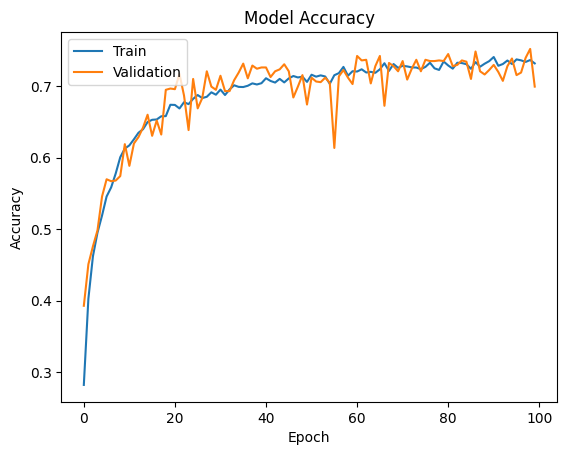

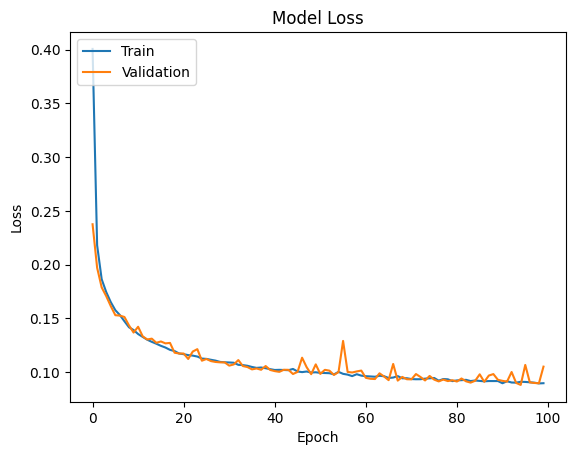

44/44 [==============================] - 0s 2ms/step - loss: 0.0998 - accuracy: 0.7079
Точность модели на тестовой выборке: 70.79


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical
import matplotlib.pyplot as plt

from tensorflow.keras.optimizers import SGD
from tensorflow.keras.losses import MeanSquaredError

from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.losses import BinaryCrossentropy

from tensorflow.keras.optimizers import Adagrad
from tensorflow.keras.losses import KLDivergence

# Загрузка базы данных из Excel
data = pd.read_excel('dataBase.xlsx')

# Удаление нулевой строки
data = data.iloc[1:]

# Определение входных и выходных данных
features = data.iloc[:, :24]  # Выбираем столбцы с 1 по 24
labels = data.iloc[:, 26]    # Выбираем столбец 26

# Предобработка категориальной переменной "пол"
le = LabelEncoder()
features['пол'] = le.fit_transform(features['пол'])

# Преобразование меток классов в one-hot encoding
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)
labels_one_hot = to_categorical(labels_encoded)

# Разделение на обучающую, тестовую и валидационную выборки
X_train, X_test, y_train, y_test = train_test_split(features, labels_one_hot, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Создание нейронной сети
model = Sequential()
model.add(Dense(64, activation='relu', input_dim=24))
model.add(Dense(64, activation='relu'))
model.add(Dense(13, activation='softmax'))

# Компиляция модели
model.compile(optimizer=SGD(), loss=BinaryCrossentropy(), metrics=['accuracy'])

# Обучение модели
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val))

# сохранение модели
model.save('model1.h5')

# График точности модели на обучающей и валидационной выборках
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# График потерь модели на обучающей и валидационной выборках
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Оценка модели на тестовой выборке
_, accuracy = model.evaluate(X_test, y_test)
print('Точность модели на тестовой выборке: %.2f' % (accuracy * 100))